## Advanced Machine Learning Alternative Assesment
### Haziq


In [1]:
import os
import sys
import shutil
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')


import numpy as np
import pandas as pd
from collections import Counter, defaultdict
import random
from tqdm.auto import tqdm
import json


import cv2
from PIL import Image, ImageEnhance
import albumentations as A
from albumentations.pytorch import ToTensorV2


import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
from sklearn.metrics import confusion_matrix


import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms



# Plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 6)

In [2]:

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print(f"Using device: {device}")

if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
elif device.type == 'mps':
    print("Using Apple Silicon GPU acceleration (MPS)")
else:
    print("Using CPU")

Using device: mps
Using Apple Silicon GPU acceleration (MPS)


In [3]:
# Dataset paths
DATASET_ROOT = 'skin-lesion-segmentation-classification'
TRAIN_IMAGES = os.path.join(DATASET_ROOT, 'train','images')
TRAIN_LABELS = os.path.join(DATASET_ROOT,'train','labels')
BALANCED_TRAIN_IMAGES = os.path.join(DATASET_ROOT, 'balanced_train','images')
BALANCED_TRAIN_LABELS = os.path.join(DATASET_ROOT,'balanced_train','labels')
YOLO_TRAIN_LABELS = os.path.join(DATASET_ROOT,'yolo_train','labels')
VAL_IMAGES = os.path.join(DATASET_ROOT,'valid','images')
VAL_LABELS = os.path.join(DATASET_ROOT, 'valid','labels')
YOLO_VAL_LABELS = os.path.join(DATASET_ROOT,'yolo_val','labels')
TEST_IMAGES = os.path.join(DATASET_ROOT, 'test','images')
TEST_LABELS = os.path.join(DATASET_ROOT, 'test','labels')

# Class definitions
CLASS_NAMES = {
    0: 'BKL - Benign Keratosis',
    1: 'NV - Melanocytic Nevi',
    2: 'DF - Dermatofibroma',
    3: 'MEL - Melanoma',
    4: 'VASC - Vascular Lesion',
    5: 'BCC - Basal Cell Carcinoma',
    6: 'AKIEC - Actinic Keratoses'
}

CLASS_CODES = {0: 'BKL', 1: 'NV', 2: 'DF', 3: 'MEL', 4: 'VASC', 5: 'BCC', 6: 'AKIEC'}
CLASS_SEVERITY = {0: 'Benign', 1: 'Benign', 2: 'Benign', 3: 'Malignant (Critical)', 
                  4: 'Benign', 5: 'Malignant', 6: 'Precancerous'}


# Augmentation settings
IMAGE_SIZE = 224  # Target size for training

print(f"Dataset: {DATASET_ROOT}")
print(f"Image size: {IMAGE_SIZE}x{IMAGE_SIZE}")

Dataset: skin-lesion-segmentation-classification
Image size: 224x224


In [4]:
def parse_yolo_label(label_path):
    """Parse YOLO format annotation"""
    annotations = []
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    annotations.append({
                        'class_id': int(parts[0]),
                        'x_center': float(parts[1]),
                        'y_center': float(parts[2]),
                        'width': float(parts[3]),
                        'height': float(parts[4])
                    })
    return annotations


def save_yolo_label(label_path, annotations):
    """Save annotations in YOLO format"""
    with open(label_path, 'w') as f:
        for ann in annotations:
            f.write(f"{ann['class_id']} {ann['x_center']:.6f} {ann['y_center']:.6f} "
                   f"{ann['width']:.6f} {ann['height']:.6f}\n")


def load_dataset_info(train_image,train_labels):
    """Load dataset and analyze class distribution"""
    data = []
    
    image_files = [f for f in os.listdir(train_image) 
                   if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    
    print(f"Loading dataset information from {len(image_files)} images...")
    
    for img_file in tqdm(image_files, desc="Processing"):
        img_path = os.path.join(train_image, img_file)
        label_path = os.path.join(train_labels, os.path.splitext(img_file)[0] + '.txt')
        
        annotations = parse_yolo_label(label_path)
        
        if annotations:
            for ann in annotations:
                data.append({
                    'filename': img_file,
                    'class_id': ann['class_id'],
                    'class_code': CLASS_CODES[ann['class_id']],
                    'severity': CLASS_SEVERITY[ann['class_id']],
                    'bbox': ann
                })
    
    df = pd.DataFrame(data)
    print(f"\n✅ Loaded {len(df)} annotations from {df['filename'].nunique()} images")
    
    return df

In [5]:
# Load dataset
df = load_dataset_info(train_image=TRAIN_IMAGES, train_labels=TRAIN_LABELS)

# Analyze class distribution
class_counts = df.groupby('class_id').size().to_dict()
total_samples = len(df)

print("CLASS DISTRIBUTION ANALYSIS")

class_dist = df.groupby(['class_id', 'class_code', 'severity']).size().reset_index(name='count')
class_dist['percentage'] = (class_dist['count'] / total_samples * 100).round(2)
class_dist = class_dist.sort_values('count', ascending=False)

display(class_dist)

# Calculate imbalance metrics
max_count = class_dist['count'].max()
min_count = class_dist['count'].min()
imbalance_ratio = max_count / min_count

print(f"Imbalance Metrics:")
print(f"Most common: {class_dist.iloc[0]['class_code']} with {max_count} samples")
print(f"Least common: {class_dist.iloc[-1]['class_code']} with {min_count} samples")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")


Loading dataset information from 6675 images...


Processing: 100%|██████████| 6675/6675 [00:01<00:00, 6069.70it/s]


✅ Loaded 7805 annotations from 6675 images
CLASS DISTRIBUTION ANALYSIS


,class_id,class_code,severity,count,percentage
5,5,BCC,Malignant,5317,68.12
4,4,VASC,Benign,989,12.67
2,2,DF,Benign,551,7.06
1,1,NV,Benign,459,5.88
0,0,BKL,Benign,260,3.33
6,6,AKIEC,Precancerous,121,1.55
3,3,MEL,Malignant (Critical),108,1.38


Imbalance Metrics:
Most common: BCC with 5317 samples
Least common: MEL with 108 samples
Imbalance ratio: 49.23:1


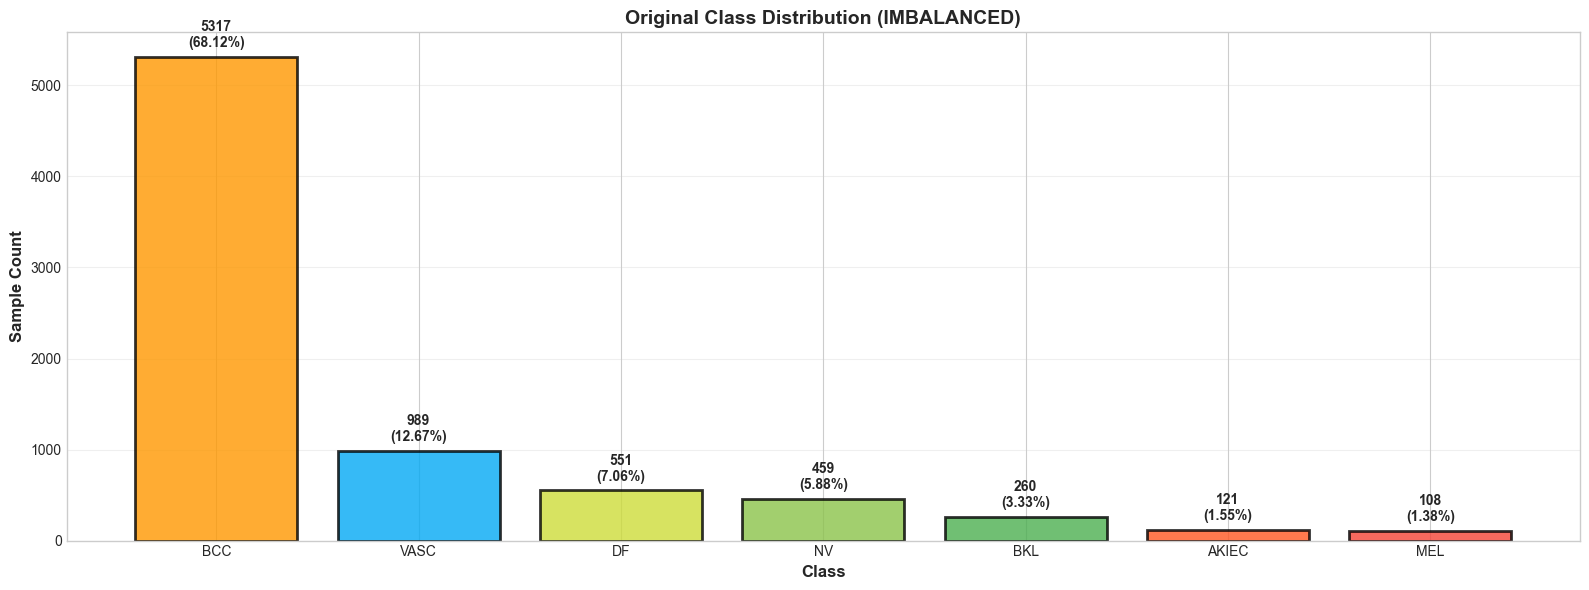

Saved visualization: 01_original_imbalance.png


In [6]:
# Visualize current imbalance
fig, (ax1) = plt.subplots(1, 1, figsize=(16, 6))

# Bar chart
colors = ['#4CAF50', '#8BC34A', '#CDDC39', '#F44336', '#03A9F4', '#FF9800', '#FF5722']
class_colors = [colors[i] for i in class_dist['class_id']]

bars = ax1.bar(class_dist['class_code'], class_dist['count'], 
               color=class_colors, edgecolor='black', linewidth=2, alpha=0.8)
ax1.set_xlabel('Class', fontweight='bold', fontsize=12)
ax1.set_ylabel('Sample Count', fontweight='bold', fontsize=12)
ax1.set_title('Original Class Distribution (IMBALANCED)', fontweight='bold', fontsize=14)
ax1.grid(axis='y', alpha=0.3)

for i, row in class_dist.iterrows():
    ax1.text(row['class_code'], row['count'] + max_count*0.02,
             f"{row['count']}\n({row['percentage']}%)",
             ha='center', fontweight='bold', fontsize=10)



plt.tight_layout()
plt.savefig('01_original_imbalance.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved visualization: 01_original_imbalance.png")

In [7]:
def get_augmentation_pipeline(image_size=224):
    return A.Compose(
        [
            A.Rotate(limit=180, border_mode=cv2.BORDER_CONSTANT, p=0.8),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomResizedCrop(
                size=(image_size, image_size),
                scale=(0.9, 1.0),
                ratio=(0.95, 1.05),
                p=0.5,
            ),
            A.ColorJitter(
                brightness=0.2,
                contrast=0.2,
                saturation=0.2,
                hue=0.05,
                p=0.6,
            ),
            A.GaussianBlur(blur_limit=(3, 5), p=0.3),
            A.Resize(height=image_size, width=image_size, p=1.0),
        ],
        bbox_params=A.BboxParams(
            format="yolo",
            label_fields=["class_labels"],
            min_visibility=0.3,
            check_each_transform=True,
        ),
    )

augmentation_pipeline = get_augmentation_pipeline()

In [8]:
import os
import shutil
from collections import defaultdict
import random

def create_capped_yolo_dataset(
    src_images_dir,
    src_labels_dir,
    dst_images_dir,
    dst_labels_dir,
    max_per_class=500,
    seed=42,
):
    random.seed(seed)

    os.makedirs(dst_images_dir, exist_ok=True)
    os.makedirs(dst_labels_dir, exist_ok=True)

    # Track how many samples per class we have copied
    class_counts = defaultdict(int)

    label_files = [f for f in os.listdir(src_labels_dir) if f.endswith(".txt")]
    random.shuffle(label_files)

    for label_file in label_files:
        label_path = os.path.join(src_labels_dir, label_file)

        with open(label_path, "r") as f:
            lines = f.readlines()

        if not lines:
            continue

        classes_in_image = set(int(line.split()[0]) for line in lines)

        # Check if adding this image would exceed any class cap
        if all(class_counts[c] >= max_per_class for c in classes_in_image):
            continue

        # Copy image
        image_name = os.path.splitext(label_file)[0]
        for ext in [".jpg", ".png", ".jpeg"]:
            src_img_path = os.path.join(src_images_dir, image_name + ext)
            if os.path.exists(src_img_path):
                dst_img_path = os.path.join(dst_images_dir, image_name + ext)
                shutil.copy(src_img_path, dst_img_path)
                break
        else:
            # Image not found
            continue

        # Copy label
        shutil.copy(
            label_path,
            os.path.join(dst_labels_dir, label_file),
        )

        # Update counts
        for c in classes_in_image:
            if class_counts[c] < max_per_class:
                class_counts[c] += 1

        # Early exit if all classes are capped
        if all(count >= max_per_class for count in class_counts.values()):
            break

    print("Final class counts:")
    for cls, count in sorted(class_counts.items()):
        print(f"Class {cls}: {count}")


In [9]:
create_capped_yolo_dataset(
    src_images_dir=TRAIN_IMAGES,
    src_labels_dir=TRAIN_LABELS,
    dst_images_dir=BALANCED_TRAIN_IMAGES,
    dst_labels_dir=BALANCED_TRAIN_LABELS,
    max_per_class=500,
)


Final class counts:
Class 0: 217
Class 1: 361
Class 2: 446
Class 3: 82
Class 4: 500
Class 5: 500
Class 6: 106


In [10]:
# Load dataset
df = load_dataset_info(train_image=BALANCED_TRAIN_IMAGES, train_labels=BALANCED_TRAIN_LABELS)

# Analyze class distribution
class_counts = df.groupby('class_id').size().to_dict()
total_samples = len(df)

print("CLASS DISTRIBUTION ANALYSIS")

class_dist = df.groupby(['class_id', 'class_code', 'severity']).size().reset_index(name='count')
class_dist['percentage'] = (class_dist['count'] / total_samples * 100).round(2)
class_dist = class_dist.sort_values('count', ascending=False)

display(class_dist)

# Calculate imbalance metrics
max_count = class_dist['count'].max()
min_count = class_dist['count'].min()
imbalance_ratio = max_count / min_count

print(f"Imbalance Metrics:")
print(f"Most common: {class_dist.iloc[0]['class_code']} with {max_count} samples")
print(f"Least common: {class_dist.iloc[-1]['class_code']} with {min_count} samples")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")


Loading dataset information from 2212 images...


Processing: 100%|██████████| 2212/2212 [00:00<00:00, 27486.20it/s]


✅ Loaded 2692 annotations from 2212 images
CLASS DISTRIBUTION ANALYSIS


,class_id,class_code,severity,count,percentage
4,4,VASC,Benign,628,23.33
5,5,BCC,Malignant,565,20.99
2,2,DF,Benign,551,20.47
1,1,NV,Benign,459,17.05
0,0,BKL,Benign,260,9.66
6,6,AKIEC,Precancerous,121,4.49
3,3,MEL,Malignant (Critical),108,4.01


Imbalance Metrics:
Most common: VASC with 628 samples
Least common: MEL with 108 samples
Imbalance ratio: 5.81:1


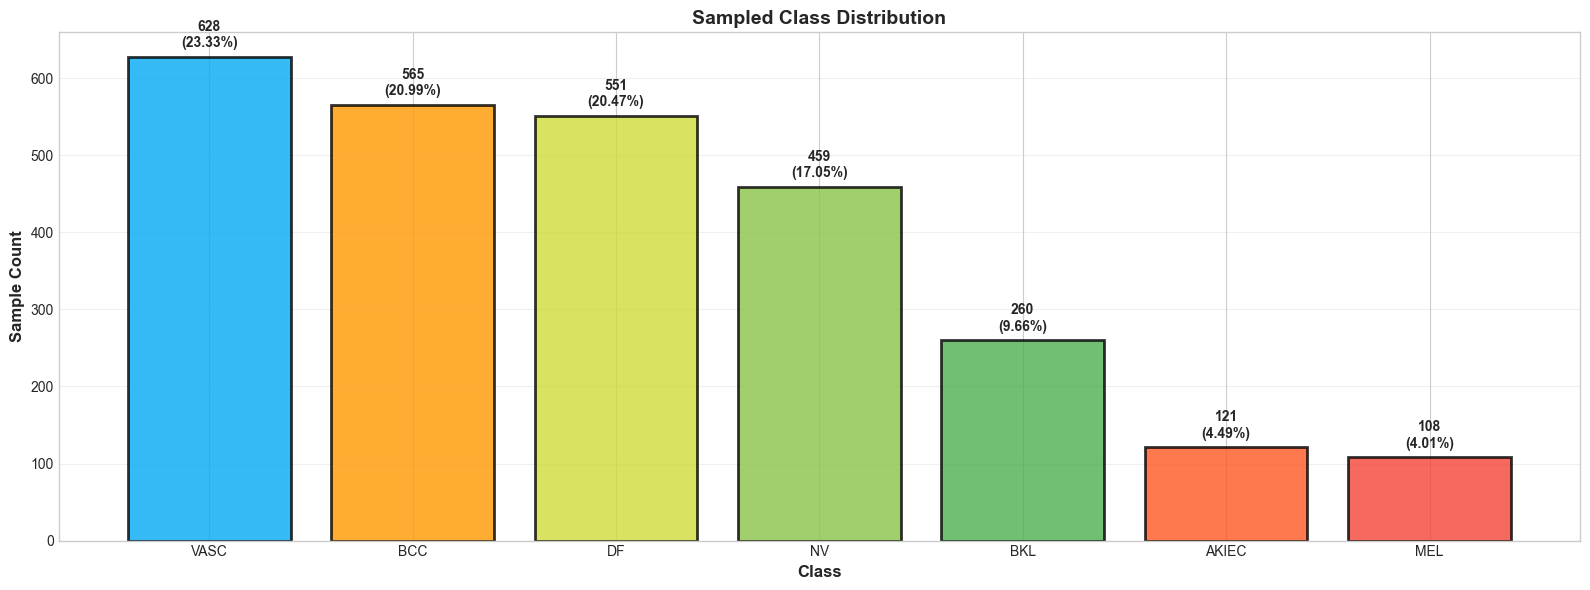

Saved visualization: 02_balanced.png


In [11]:
# Visualize current imbalance
fig, (ax1) = plt.subplots(1, 1, figsize=(16, 6))

# Bar chart
colors = ['#4CAF50', '#8BC34A', '#CDDC39', '#F44336', '#03A9F4', '#FF9800', '#FF5722']
class_colors = [colors[i] for i in class_dist['class_id']]

bars = ax1.bar(class_dist['class_code'], class_dist['count'], 
               color=class_colors, edgecolor='black', linewidth=2, alpha=0.8)
ax1.set_xlabel('Class', fontweight='bold', fontsize=12)
ax1.set_ylabel('Sample Count', fontweight='bold', fontsize=12)
ax1.set_title('Sampled Class Distribution', fontweight='bold', fontsize=14)
ax1.grid(axis='y', alpha=0.3)

for i, row in class_dist.iterrows():
    ax1.text(row['class_code'], row['count'] + max_count*0.02,
             f"{row['count']}\n({row['percentage']}%)",
             ha='center', fontweight='bold', fontsize=10)



plt.tight_layout()
plt.savefig('02_balanced.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved visualization: 02_balanced.png")

In [12]:
import os
import cv2
import torch
from torch.utils.data import Dataset
from torchvision import transforms

def parse_yolo_label(label_path):
    """
    Reads YOLO label file and returns class_id (int).
    Assumes one object per image.
    """
    if not os.path.exists(label_path):
        return None

    with open(label_path, "r") as f:
        line = f.readline().strip()

    if not line:
        return None

    return int(line.split()[0])


In [13]:
class LesionClassificationDataset(Dataset):
    def __init__(self, images_dir, labels_dir, transform=None):
        self.images_dir = images_dir
        self.labels_dir = labels_dir
        self.transform = transform

        self.samples = []

        for img_name in os.listdir(images_dir):
            if not img_name.lower().endswith((".jpg", ".png", ".jpeg")):
                continue

            label_path = os.path.join(
                labels_dir,
                os.path.splitext(img_name)[0] + ".txt"
            )

            label = parse_yolo_label(label_path)
            if label is not None:
                self.samples.append((img_name, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_name, label = self.samples[idx]

        img_path = os.path.join(self.images_dir, img_name)
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image)
        else:
            image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0

        return image, label


In [14]:
train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(0.1, 0.1, 0.1),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [15]:
from torch.utils.data import DataLoader

train_dataset = LesionClassificationDataset(
    images_dir=BALANCED_TRAIN_IMAGES,
    labels_dir=BALANCED_TRAIN_LABELS,
    transform=train_transform
)

val_dataset = LesionClassificationDataset(
    images_dir=VAL_IMAGES,
    labels_dir=VAL_LABELS,
    transform=val_transform
)

test_dataset = LesionClassificationDataset(
    images_dir=TEST_IMAGES,
    labels_dir=TEST_LABELS,
    transform=val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0   # IMPORTANT on macOS
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Train samples:", len(train_dataset))
print("Val samples:", len(val_dataset))


Train samples: 2212
Val samples: 1911


In [16]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

num_classes = 7  # your lesion classes

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)


In [17]:
for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)


In [18]:
from collections import Counter

labels = [lbl for _, lbl in train_dataset.samples]
class_counts = Counter(labels)

weights = torch.tensor(
    [1.0 / class_counts[i] for i in range(num_classes)],
    dtype=torch.float
).to(device)

criterion = nn.CrossEntropyLoss(weight=weights)

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=1e-3
)


In [19]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


In [20]:
@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


In [21]:
for param in model.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


In [22]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        """
        patience: number of epochs to wait after last improvement
        min_delta: minimum change to qualify as improvement
        """
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.should_stop = False

    def step(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            return True  # improvement
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
            return False


In [23]:
EPOCHS = 50
early_stopper = EarlyStopping(patience=6, min_delta=1e-4)

best_val_loss = float("inf")

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, device
    )

    val_loss, val_acc = validate(
        model, val_loader, criterion, device
    )

    # Store history
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}"
    )

    # Early stopping check
    improved = early_stopper.step(val_loss)

    if improved:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_resnet_classifier.pth")
        print("✔ Validation loss improved — model saved")

    if early_stopper.should_stop:
        print(f"⏹ Early stopping triggered at epoch {epoch+1}")
        break


Epoch [1/50] | Train Loss: 1.1895, Acc: 0.5072 | Val Loss: 0.8261, Acc: 0.7143
✔ Validation loss improved — model saved
Epoch [2/50] | Train Loss: 0.7057, Acc: 0.6985 | Val Loss: 0.8180, Acc: 0.6719
✔ Validation loss improved — model saved
Epoch [3/50] | Train Loss: 0.5686, Acc: 0.7464 | Val Loss: 0.6358, Acc: 0.7640
✔ Validation loss improved — model saved
Epoch [4/50] | Train Loss: 0.4001, Acc: 0.8269 | Val Loss: 0.7123, Acc: 0.7300
Epoch [5/50] | Train Loss: 0.3280, Acc: 0.8585 | Val Loss: 0.6111, Acc: 0.7807
✔ Validation loss improved — model saved
Epoch [6/50] | Train Loss: 0.2892, Acc: 0.8721 | Val Loss: 0.7606, Acc: 0.7373
Epoch [7/50] | Train Loss: 0.2407, Acc: 0.8897 | Val Loss: 0.7490, Acc: 0.7415
Epoch [8/50] | Train Loss: 0.2098, Acc: 0.9123 | Val Loss: 0.7622, Acc: 0.7609
Epoch [9/50] | Train Loss: 0.1681, Acc: 0.9299 | Val Loss: 0.6286, Acc: 0.7645
Epoch [10/50] | Train Loss: 0.1662, Acc: 0.9268 | Val Loss: 0.6586, Acc: 0.7891
Epoch [11/50] | Train Loss: 0.1242, Acc: 0.95

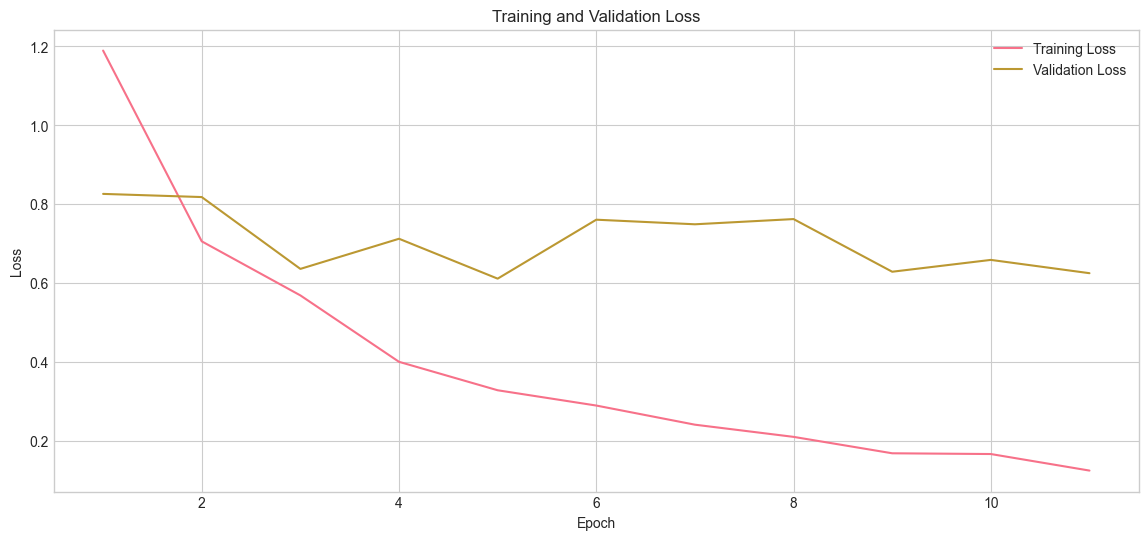

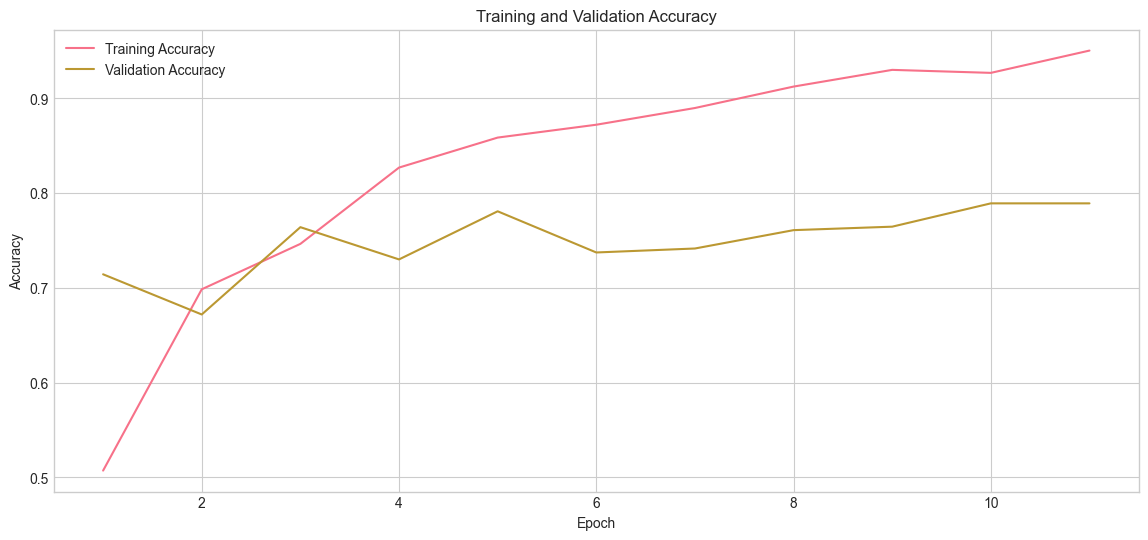

In [24]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# Plot Loss
plt.figure()
plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Plot Accuracy
plt.figure()
plt.plot(epochs, history["train_acc"], label="Training Accuracy")
plt.plot(epochs, history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


In [25]:
import torch
import numpy as np

@torch.no_grad()
def get_test_predictions(model, dataloader, device):
    """
    Returns:
        y_true (np.ndarray)
        y_pred (np.ndarray)
    """
    model.eval()

    y_true, y_pred = [], []

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)

        y_true.append(labels.cpu().numpy())
        y_pred.append(preds.cpu().numpy())

    return np.concatenate(y_true), np.concatenate(y_pred)


In [26]:
from sklearn.metrics import accuracy_score, recall_score, f1_score

def compute_weighted_metrics(y_true, y_pred):
    """
    Computes weighted accuracy, recall, and F1 score.
    """
    return {
        "weighted_accuracy": accuracy_score(y_true, y_pred),
        "weighted_recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    }


In [27]:
from sklearn.metrics import classification_report

def compute_per_class_metrics(y_true, y_pred, class_names):
    """
    Returns a dict with per-class precision, recall, F1, and support.
    """
    report = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    return report


In [28]:
def print_per_class_metrics(report):
    print(f"{'Class':<30} {'Prec':>7} {'Recall':>7} {'F1':>7} {'Support':>9}")
    print("-" * 65)

    for cls, metrics in report.items():
        if cls in ["accuracy", "macro avg", "weighted avg"]:
            continue

        print(
            f"{cls:<30} "
            f"{metrics['precision']:>7.3f} "
            f"{metrics['recall']:>7.3f} "
            f"{metrics['f1-score']:>7.3f} "
            f"{int(metrics['support']):>9}"
        )


In [29]:
def evaluate_on_test_set(
    model,
    test_loader,
    device,
    class_names
):
    # Get predictions
    y_true, y_pred = get_test_predictions(model, test_loader, device)

    # Weighted metrics
    weighted_metrics = compute_weighted_metrics(y_true, y_pred)

    # Per-class metrics
    per_class_report = compute_per_class_metrics(
        y_true, y_pred, class_names
    )

    return weighted_metrics, per_class_report, y_true, y_pred


In [30]:
# Load best model
model.load_state_dict(
    torch.load("best_resnet_classifier.pth", map_location=device)
)
model.to(device)

weighted_metrics, per_class_report,y_true,y_pred = evaluate_on_test_set(
    model,
    test_loader, 
    device,
    CLASS_NAMES
)

print("📊 Weighted Metrics")
for k, v in weighted_metrics.items():
    print(f"{k}: {v:.4f}")

print("\n📋 Per-Class Metrics")
print_per_class_metrics(per_class_report)

📊 Weighted Metrics
weighted_accuracy: 0.7482
weighted_recall: 0.7482
weighted_f1: 0.7668

📋 Per-Class Metrics
Class                             Prec  Recall      F1   Support
-----------------------------------------------------------------
0                                0.560   0.778   0.651        36
1                                0.636   0.764   0.694        55
2                                0.458   0.688   0.550        64
3                                0.235   0.667   0.348        12
4                                0.453   0.548   0.496       115
5                                0.944   0.783   0.856       664
6                                0.560   0.933   0.700        15


In [31]:
import numpy as np

correct_info = [
    (i, y_true[i])
    for i in np.where(y_true == y_pred)[0]
]


In [32]:
correct_info

[(np.int64(0), np.int64(5)),
 (np.int64(2), np.int64(5)),
 (np.int64(3), np.int64(5)),
 (np.int64(4), np.int64(5)),
 (np.int64(6), np.int64(5)),
 (np.int64(8), np.int64(5)),
 (np.int64(9), np.int64(5)),
 (np.int64(10), np.int64(5)),
 (np.int64(11), np.int64(5)),
 (np.int64(12), np.int64(5)),
 (np.int64(14), np.int64(5)),
 (np.int64(15), np.int64(5)),
 (np.int64(17), np.int64(5)),
 (np.int64(18), np.int64(5)),
 (np.int64(19), np.int64(5)),
 (np.int64(20), np.int64(5)),
 (np.int64(22), np.int64(0)),
 (np.int64(24), np.int64(5)),
 (np.int64(25), np.int64(5)),
 (np.int64(29), np.int64(6)),
 (np.int64(30), np.int64(5)),
 (np.int64(31), np.int64(4)),
 (np.int64(32), np.int64(4)),
 (np.int64(34), np.int64(5)),
 (np.int64(35), np.int64(5)),
 (np.int64(36), np.int64(2)),
 (np.int64(37), np.int64(5)),
 (np.int64(39), np.int64(5)),
 (np.int64(40), np.int64(5)),
 (np.int64(41), np.int64(5)),
 (np.int64(42), np.int64(5)),
 (np.int64(43), np.int64(2)),
 (np.int64(44), np.int64(2)),
 (np.int64(45), n

In [42]:
items_with_class_6 = [
    item for item in correct_info if item[1] == 0
]
items_with_class_6

[(np.int64(22), np.int64(0)),
 (np.int64(92), np.int64(0)),
 (np.int64(116), np.int64(0)),
 (np.int64(134), np.int64(0)),
 (np.int64(138), np.int64(0)),
 (np.int64(145), np.int64(0)),
 (np.int64(158), np.int64(0)),
 (np.int64(221), np.int64(0)),
 (np.int64(256), np.int64(0)),
 (np.int64(295), np.int64(0)),
 (np.int64(304), np.int64(0)),
 (np.int64(399), np.int64(0)),
 (np.int64(413), np.int64(0)),
 (np.int64(425), np.int64(0)),
 (np.int64(441), np.int64(0)),
 (np.int64(447), np.int64(0)),
 (np.int64(457), np.int64(0)),
 (np.int64(496), np.int64(0)),
 (np.int64(570), np.int64(0)),
 (np.int64(619), np.int64(0)),
 (np.int64(621), np.int64(0)),
 (np.int64(628), np.int64(0)),
 (np.int64(677), np.int64(0)),
 (np.int64(683), np.int64(0)),
 (np.int64(699), np.int64(0)),
 (np.int64(727), np.int64(0)),
 (np.int64(739), np.int64(0)),
 (np.int64(743), np.int64(0))]

In [34]:
import numpy as np

correct_indices = np.where(y_true == y_pred)[0]

In [35]:
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

plt.figure()
plt.imshow(cm_norm, cmap="Reds")
plt.title("Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(ticks=np.arange(len(class_names)), labels=class_names, rotation=45)
plt.yticks(ticks=np.arange(len(class_names)), labels=class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()


NameError: name 'cm' is not defined

### GRAD CAM

In [36]:
import torch.nn.functional as F
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()

        output = self.model(input_tensor)

        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        self.model.zero_grad()
        score = output[:, class_idx]
        score.backward(retain_graph=True)

        # Global Average Pooling of gradients
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)

        cam = (weights * self.activations).sum(dim=1)
        cam = F.relu(cam)

        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() + 1e-8)

        return cam, class_idx


In [37]:
def prepare_image(image, transform, device):
    """
    image: numpy array (H, W, C), RGB
    """
    input_tensor = transform(image).unsqueeze(0)
    return input_tensor.to(device)


In [38]:
def overlay_gradcam(image, cam, alpha=0.4):
    """
    image: original RGB image (H, W, C)
    cam: Grad-CAM heatmap (h, w)
    """
    h, w, _ = image.shape
    cam_resized = cv2.resize(cam, (w, h))
    heatmap = cv2.applyColorMap(
        np.uint8(255 * cam_resized),
        cv2.COLORMAP_JET
    )

    overlay = cv2.addWeighted(image, 1 - alpha, heatmap, alpha, 0)
    return overlay


In [43]:
# 1. Load model
model.eval()
model.to(device)

# 2. Initialize Grad-CAM
gradcam = GradCAM(
    model=model,
    target_layer=model.layer4
)

# 3. Get one sample
# Dataset output
image_tensor, label = test_dataset[22]

# Reload raw image
img_name, _ = test_dataset.samples[22]
img_path = os.path.join(test_dataset.images_dir, img_name)

original_image = cv2.imread(img_path)
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

# Model input
input_tensor = image_tensor.unsqueeze(0).to(device)

# Grad-CAM
cam, pred_class = gradcam.generate(input_tensor)
overlay = overlay_gradcam(original_image, cam)



In [44]:
label, pred_class

(0, 0)

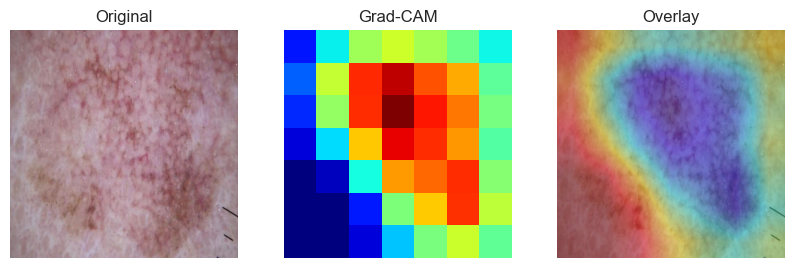

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.title("Original")
plt.imshow(original_image)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.title("Grad-CAM")
plt.imshow(cam, cmap="jet")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title("Overlay")
plt.imshow(overlay)
plt.axis("off")

plt.show()
